# Búsqueda en anchura (BFS)

Explora un grafo por niveles: primero los vecinos del origen, luego los vecinos de estos, etc. Usa una cola (`collections.deque`). En grafos no ponderados encuentra el camino más corto. Cuesta $O(V + E)$.

## 1. Recorrido por niveles

Devolver el orden en que BFS visita los nodos desde un origen.

In [1]:
from collections import deque

grafo = {
    "A": ["B", "C"],
    "B": ["A", "D", "E"],
    "C": ["A", "F"],
    "D": ["B"],
    "E": ["B", "F"],
    "F": ["C", "E"],
}

def bfs(grafo, origen):
    visitados, cola = [origen], deque([origen])
    while cola:
        for vecino in grafo[cola.popleft()]:
            if vecino not in visitados:
                visitados.append(vecino)
                cola.append(vecino)
    return visitados

print(bfs(grafo, "A"))

['A', 'B', 'C', 'D', 'E', 'F']


## 2. Camino más corto

Devolver el camino con menos aristas entre dos nodos, guardando el padre de cada nodo descubierto.

In [2]:
def camino_mas_corto(grafo, origen, destino):
    padres, cola = {origen: None}, deque([origen])
    while cola:
        nodo = cola.popleft()
        if nodo == destino:
            camino = []
            while nodo is not None:
                camino.append(nodo)
                nodo = padres[nodo]
            return camino[::-1]
        for vecino in grafo[nodo]:
            if vecino not in padres:
                padres[vecino] = nodo
                cola.append(vecino)
    return None

print(camino_mas_corto(grafo, "D", "F"))

['D', 'B', 'E', 'F']


## 3. Grados de separación

Calcular la distancia (en aristas) desde un origen a todos los nodos alcanzables.

In [3]:
def distancias(grafo, origen):
    dist, cola = {origen: 0}, deque([origen])
    while cola:
        nodo = cola.popleft()
        for vecino in grafo[nodo]:
            if vecino not in dist:
                dist[vecino] = dist[nodo] + 1
                cola.append(vecino)
    return dist

print(distancias(grafo, "A"))

{'A': 0, 'B': 1, 'C': 1, 'D': 2, 'E': 2, 'F': 2}


## 4. Camino más corto en una rejilla

Encontrar el camino más corto de `S` a `E` en una rejilla con muros `#`, moviéndose en horizontal o vertical. Guardar el padre de cada casilla para reconstruir el camino, dibujarlo con `*` y comprobar su longitud en rejillas aleatorias contra una relajación repetida de distancias (fuerza bruta).

In [4]:
import random

laberinto = [
    "S...#......",
    ".##.#.####.",
    ".#..#....#.",
    ".#.####.##.",
    ".#......#..",
    ".######.#.#",
    "........#.E",
]

def busca(rejilla, simbolo):
    return next((f, c) for f, fila in enumerate(rejilla) for c, v in enumerate(fila) if v == simbolo)

def vecinos(rejilla, f, c):
    for df, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
        nf, nc = f + df, c + dc
        if 0 <= nf < len(rejilla) and 0 <= nc < len(rejilla[0]) and rejilla[nf][nc] != "#":
            yield nf, nc

def camino_en_rejilla(rejilla, origen, destino):
    padres, cola = {origen: None}, deque([origen])
    while cola:
        nodo = cola.popleft()
        if nodo == destino:
            ruta = []
            while nodo is not None:
                ruta.append(nodo)
                nodo = padres[nodo]
            return ruta[::-1]
        for v in vecinos(rejilla, *nodo):
            if v not in padres:
                padres[v] = nodo
                cola.append(v)
    return None

def dibuja(rejilla, ruta):
    filas = [list(fila) for fila in rejilla]
    for f, c in ruta[1:-1]:
        filas[f][c] = "*"
    print("\n".join("".join(fila) for fila in filas))

def distancia_fuerza_bruta(rejilla, origen, destino):
    libres = [(f, c) for f in range(len(rejilla)) for c in range(len(rejilla[0])) if rejilla[f][c] != "#"]
    dist = {v: float("inf") for v in libres}
    dist[origen], cambio = 0, True
    while cambio:
        cambio = False
        for u in libres:
            for v in vecinos(rejilla, *u):
                if dist[u] + 1 < dist[v]:
                    dist[v], cambio = dist[u] + 1, True
    return dist[destino]

ruta = camino_en_rejilla(laberinto, busca(laberinto, "S"), busca(laberinto, "E"))
print("Pasos:", len(ruta) - 1)
dibuja(laberinto, ruta)

random.seed(4)
for _ in range(200):
    r = [["#" if random.random() < 0.3 else "." for _ in range(8)] for _ in range(6)]
    r[0][0] = r[5][7] = "."
    camino_r = camino_en_rejilla(r, (0, 0), (5, 7))
    esperado = distancia_fuerza_bruta(r, (0, 0), (5, 7))
    if camino_r is None:
        assert esperado == float("inf")
    else:
        assert len(camino_r) - 1 == esperado
        assert all(b in vecinos(r, *a) for a, b in zip(camino_r, camino_r[1:]))

Pasos: 32
S***#******
.##*#*####*
.#**#***.#*
.#*####*##*
.#******#**
.######.#*#
........#*E


## 5. BFS multiorigen

Calcular, para cada casilla libre de una ciudad, la distancia al hospital más cercano. En lugar de lanzar un BFS por hospital, meter todos los orígenes en la cola con distancia 0: un único BFS en $O(V + E)$. Comprobarlo contra el mínimo de los BFS individuales y dibujar el mapa de distancias.

Casilla más alejada de un hospital: (19, 0) a 21 pasos


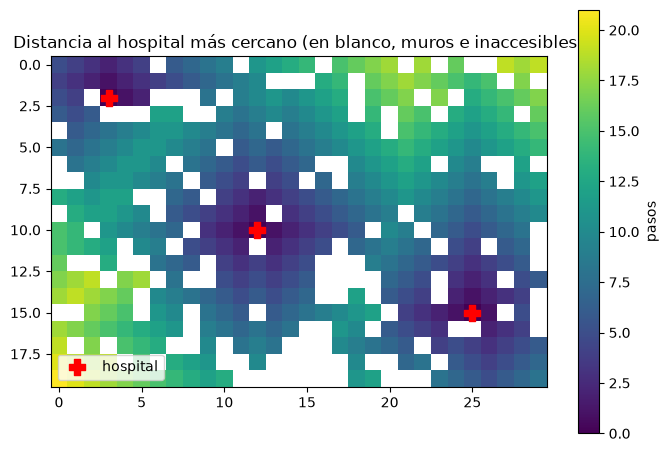

In [5]:
import matplotlib.pyplot as plt

def bfs_multiorigen(rejilla, origenes):
    dist, cola = {o: 0 for o in origenes}, deque(origenes)
    while cola:
        nodo = cola.popleft()
        for v in vecinos(rejilla, *nodo):
            if v not in dist:
                dist[v] = dist[nodo] + 1
                cola.append(v)
    return dist

random.seed(5)
filas, columnas = 20, 30
ciudad = [["#" if random.random() < 0.2 else "." for _ in range(columnas)] for _ in range(filas)]
hospitales = [(2, 3), (15, 25), (10, 12)]
for f, c in hospitales:
    ciudad[f][c] = "."

dist = bfs_multiorigen(ciudad, hospitales)
individuales = [bfs_multiorigen(ciudad, [h]) for h in hospitales]
assert set(dist) == set().union(*individuales)
for casilla, d in dist.items():
    assert d == min(ind.get(casilla, float("inf")) for ind in individuales)

lejana = max(dist, key=dist.get)
print("Casilla más alejada de un hospital:", lejana, "a", dist[lejana], "pasos")

mapa = [[dist.get((f, c), float("nan")) for c in range(columnas)] for f in range(filas)]
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(mapa, cmap="viridis")
ax.scatter([c for _, c in hospitales], [f for f, _ in hospitales], marker="P", s=120, color="red", label="hospital")
ax.set_title("Distancia al hospital más cercano (en blanco, muros e inaccesibles)")
ax.legend(loc="lower left")
fig.colorbar(im, ax=ax, label="pasos")
plt.show()

## 6. Niveles de un árbol

Agrupar los nodos de un árbol (un organigrama) por niveles procesando en cada vuelta todos los nodos que hay en la cola. Calcular la altura y el nivel más ancho, y comprobar en árboles aleatorios que el resultado coincide con un recorrido en profundidad que anota la profundidad de cada nodo.

In [6]:
organigrama = {
    "Dirección": ["Ventas", "Técnica", "Personas"],
    "Ventas": ["Ana", "Luis"],
    "Técnica": ["Backend", "Frontend"],
    "Personas": [],
    "Backend": ["Eva", "Pau", "Iker"],
    "Frontend": ["Sara"],
    "Ana": [], "Luis": [], "Eva": [], "Pau": [], "Iker": [], "Sara": [],
}

def niveles(arbol, raiz):
    resultado, cola = [], deque([raiz])
    while cola:
        # todo lo que hay ahora en la cola es del mismo nivel
        nivel = [cola.popleft() for _ in range(len(cola))]
        resultado.append(nivel)
        for nodo in nivel:
            cola.extend(arbol[nodo])
    return resultado

def niveles_dfs(arbol, nodo, profundidad=0, resultado=None):
    if resultado is None:
        resultado = []
    if profundidad == len(resultado):
        resultado.append([])
    resultado[profundidad].append(nodo)
    for hijo in arbol[nodo]:
        niveles_dfs(arbol, hijo, profundidad + 1, resultado)
    return resultado

por_niveles = niveles(organigrama, "Dirección")
for i, nivel in enumerate(por_niveles):
    print(i, nivel)
print("Altura:", len(por_niveles) - 1, " nivel más ancho:", max(por_niveles, key=len))

def arbol_aleatorio(n):
    arbol = {i: [] for i in range(n)}
    for i in range(1, n):
        arbol[random.randrange(i)].append(i)
    return arbol

random.seed(6)
for _ in range(300):
    a = arbol_aleatorio(random.randint(1, 30))
    assert niveles(a, 0) == niveles_dfs(a, 0)

0 ['Dirección']
1 ['Ventas', 'Técnica', 'Personas']
2 ['Ana', 'Luis', 'Backend', 'Frontend']
3 ['Eva', 'Pau', 'Iker', 'Sara']
Altura: 3  nivel más ancho: ['Ana', 'Luis', 'Backend', 'Frontend']


## 7. Escalera de palabras

Transformar una palabra en otra cambiando una letra cada vez y pasando solo por palabras del diccionario, con el menor número de pasos. Construir el grafo de palabras generando las variantes de cada una, buscar con `camino_mas_corto` (ejercicio 2) y comprobar todas las parejas contra las distancias de Floyd-Warshall sobre el grafo construido comparando cada par de palabras.

In [7]:
palabras = {
    "casa", "cama", "cara", "caro", "cero", "pero", "pelo", "pala", "pasa", "masa", "mesa",
    "pesa", "peso", "paso", "piso", "pisa", "risa", "rosa", "ropa", "copa", "capa", "cola",
    "colo", "codo", "coro", "loro", "lobo", "lodo", "modo", "mudo", "muro", "puro", "pura", "luna",
}

def grafo_de_palabras(diccionario):
    grafo_p = {}
    for palabra in diccionario:
        variantes = (palabra[:i] + letra + palabra[i + 1:] for i in range(len(palabra)) for letra in "abcdefghijklmnñopqrstuvwxyz")
        grafo_p[palabra] = sorted({v for v in variantes if v != palabra and v in diccionario})
    return grafo_p

grafo_p = grafo_de_palabras(palabras)
for inicio, fin in [("casa", "pelo"), ("lobo", "puro"), ("rosa", "cero"), ("casa", "luna")]:
    escalera = camino_mas_corto(grafo_p, inicio, fin)
    print(" → ".join(escalera) if escalera else f"{inicio} → {fin}: sin escalera")

def difieren_en_una(a, b):
    return sum(x != y for x, y in zip(a, b)) == 1

lista, inf = sorted(palabras), float("inf")
d = {(a, b): 0 if a == b else (1 if difieren_en_una(a, b) else inf) for a in lista for b in lista}
for k in lista:
    for a in lista:
        for b in lista:
            d[a, b] = min(d[a, b], d[a, k] + d[k, b])
for a in lista:
    for b in lista:
        escalera = camino_mas_corto(grafo_p, a, b)
        assert (escalera is None) == (d[a, b] == inf)
        assert escalera is None or (len(escalera) - 1 == d[a, b] and all(difieren_en_una(x, y) for x, y in zip(escalera, escalera[1:])))

casa → pasa → paso → peso → pelo
lobo → lodo → modo → mudo → muro → puro
rosa → risa → pisa → pesa → peso → pero → cero
casa → luna: sin escalera
